# Up or Down? Three Experiments, One Question

Here's a [question from Cross Validated](https://stats.stackexchange.com/questions/677739), the statistics Q&A site:

> We're doing an animal behavior experiment with insects placed in the middle of a vertical tube and given the binary choice to move either up or down. [...]
>
> [Up + no bait] VS. [Down + no bait]
> [Up + bait] VS. [Down + bait]
> [Up + no bait] VS. [Down + bait]
>
> Let's say 10+ trials for each condition, each time with a unique individual. The goal is to determine whether preference for presence of bait (i.e., attractant) overcomes directional preference to go up. [...] it's not so clear to me how I analyze the combined data from these three scenarios in one test [...]

To restate: each insect is put in the middle of a vertical tube and goes up or down. Insects tend to go up. The question is whether bait at the bottom pulls them down strongly enough to overcome that tendency. There are three setups -- no bait, bait at both ends, and bait only at the bottom -- with about 10 insects in each, and the researcher wants to combine them in one analysis.

The experiment hasn't been run yet, so this is a good time to ask what the data will be able to tell us. I'll show that:

1. Combining the three setups in one model doesn't give more information about the main question than setup 3 alone.
2. With 10 insects, setup 3 is unlikely to give a significant result even if the bait overcomes the up-bias.
3. A Bayesian analysis states how strong the evidence is, which is more useful than a yes-or-no test with this little data.

[Click here to run this notebook on Colab](https://colab.research.google.com/github/AllenDowney/DataQnA/blob/main/nb/dual_choice.ipynb).

I'll download a utilities module with some of my frequently-used functions, install PyMC if we're running on Colab, and then import the libraries we'll need.

In [1]:
from os.path import basename, exists

def download(url):
    filename = basename(url)
    if not exists(filename):
        from urllib.request import urlretrieve

        local, _ = urlretrieve(url, filename)
        print("Downloaded " + str(local))
    return filename

download('https://github.com/AllenDowney/DataQnA/raw/main/nb/utils.py');

In [2]:
# on Colab, upgrade the sampling stack together (PyMC 6 uses nutpie when it's installed)

import sys

if "google.colab" in sys.modules:
    %pip install -q "pymc>=6" "arviz>=1.1" nutpie

In [3]:
import numpy as np
np.set_printoptions(legacy='1.25')
import matplotlib.pyplot as plt
import pandas as pd

import pymc as pm
import statsmodels.formula.api as smf
from scipy.stats import beta, binom, binomtest

from utils import decorate

BLUE, ORANGE = "#2a78d6", "#eb6834"

## The setups as a 2×2 design

One answer to the question points out that the three setups are cells of a 2×2 design. One factor is bait at the top (yes or no); the other is bait at the bottom (yes or no). The outcome is whether each insect goes up.

| | no bait at bottom | bait at bottom |
|---|---|---|
| **no bait at top** | setup 1 | setup 3 |
| **bait at top** | *(not planned)* | setup 2 |

To have something to work with, suppose the results come out like this (made-up numbers, 10 insects per setup):

In [4]:
cells = pd.DataFrame(
    {
        "setup": [1, 2, 3],
        "bait_top": [0, 1, 0],
        "bait_bottom": [0, 1, 1],
        "up": [7, 6, 3],
        "n": [10, 10, 10],
    }
).set_index("setup")
cells["fraction up"] = cells["up"] / cells["n"]
cells

,bait_top,bait_bottom,up,n,fraction up
setup,,,,,
1,0,0,7,10,0.7
2,1,1,6,10,0.6
3,0,1,3,10,0.3


With no bait, 7 of 10 go up; with bait at the bottom, only 3 of 10 do.

The natural way to combine the setups is a logistic regression with one row per insect, as the existing answers suggest:

$$\text{logit}\, P(\text{up}) = a + b_\text{top}\, \text{top} + b_\text{bottom}\, \text{bottom}$$

where top and bottom are 1 if there's bait at that end and 0 otherwise. Here $a$ is the up-bias with no bait, and $b_\text{bottom}$ is how much bait at the bottom pulls insects down, on the log-odds scale.

In [5]:
def one_row_per_insect(cells):
    rows = []
    for cell in cells.itertuples():
        for i in range(cell.n):
            rows.append({
                "bait_top": cell.bait_top,
                "bait_bottom": cell.bait_bottom,
                "up": int(i < cell.up),
            })
    return pd.DataFrame(rows)


insects = one_row_per_insect(cells)
model = smf.logit("up ~ bait_top + bait_bottom", data=insects).fit(disp=False)
model.params

Intercept      0.847298
bait_top       1.252763
bait_bottom   -1.694596
dtype: float64

## What the combined model can't do

There are two related questions here. Does bait at the bottom make insects less likely to go up? That's a comparison between setups 1 and 3, and it takes both of them. But the researcher asks a more specific question: does the bait *overcome* the tendency to go up? I'll interpret that as asking whether fewer than half of the insects go up when the bait is at the bottom.

In the model, that means the pull of the bait is bigger than the up-bias, $|b_\text{bottom}| > a$, or equivalently $a + b_\text{bottom} < 0$. But $a + b_\text{bottom}$ is just the log odds of going up in setup 3. So under this interpretation, setup 3 answers the question directly.

The model has three parameters and the data have three observed proportions, so the model can reproduce all three exactly -- it's saturated. Its predictions are the observed proportions:

In [6]:
model.predict(cells)

setup
1    0.7
2    0.6
3    0.3
dtype: float64

And its estimate of $a + b_\text{bottom}$ is the log odds of the observed proportion in setup 3, $\log(3/7)$:

In [7]:
model.t_test("Intercept + bait_bottom = 0")

<class 'statsmodels.stats.contrast.ContrastResults'>
                             Test for Constraints                             
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
c0            -0.8473      0.690     -1.228      0.220      -2.200       0.505

In [8]:
np.log(3 / 7)

-0.8472978603872037

So the combined model gives the same estimate for the main question as setup 3 alone. (Its p-value, 0.22, is bigger than the binomial test's below because it's two-sided and uses a normal approximation.) Setups 1 and 2 don't contribute, because a saturated model has no way to borrow information from one cell to estimate another: setup 1 pins down $a$, setup 3 then pins down $b_\text{bottom}$, and setup 2 pins down $b_\text{top}$. They answer other questions -- how strong the up-bias is without bait, and whether bait at both ends changes behavior -- which are worth knowing, and setup 1 is needed to measure how much the bait changes behavior. But they don't make the test of the main hypothesis more powerful.

One of the existing answers suggests adding an interaction term. With three cells, that model has four parameters, which is more than the data can determine, so it can't be estimated (statsmodels reports a singular matrix).

## How much can 10 insects tell us?

Since the main question comes down to setup 3, the next question is whether 10 insects are enough to answer it. A one-sided binomial test of whether fewer than half go up, with 3 of 10 going up, gives:

In [9]:
binomtest(3, 10, 0.5, alternative="less").pvalue

0.171875

That's not significant. Even 2 of 10 isn't quite enough (p = 0.055); only 0 or 1 of 10 would be significant at the 0.05 level.

To see whether that's a problem with the data or with the design, suppose the bait really does overcome the up-bias, and 30% of insects go up in setup 3. The following function computes the probability of a significant result -- the power of the test -- for a given number of insects.

In [10]:
def power(n, p_up=0.3, alpha=0.05):
    ks = np.arange(n + 1)
    critical = ks[binom.cdf(ks, n, 0.5) <= alpha].max()  # largest count that's significant
    return binom.cdf(critical, n, p_up)


pd.Series({n: power(n) for n in [10, 20, 30, 50]}, name="power").rename_axis("insects").round(2)

insects
10    0.15
20    0.42
30    0.73
50    0.86
Name: power, dtype: float64

With 10 insects, the chance of a significant result is about 15%, even though, by assumption, the bait overcomes the up-bias. With 30 insects it's about 73%, and with 50 it's about 86%. So 10 per setup is not enough to expect a clear answer from a significance test.

## A Bayesian answer

When the data are this limited, a yes-or-no test is not very informative. A non-significant result doesn't mean the bait fails to overcome the up-bias; it might mean we didn't have enough insects. What we want to know is how confident we can be that the bait wins, and how big the effect might be.

With a uniform prior on the proportion of insects that go up in setup 3, the posterior after $k$ of $n$ go up is a beta distribution with parameters $k+1$ and $n-k+1$. Here's the posterior after 3 of 10, and after 9 of 30, the same proportion with three times the data:

In [11]:
posteriors = {"3 of 10": beta(3 + 1, 7 + 1), "9 of 30": beta(9 + 1, 21 + 1)}

rows = {}
for label, post in posteriors.items():
    low, high = post.ppf([0.05, 0.95])
    rows[label] = {"P(fraction up < 0.5)": post.cdf(0.5), "90% CI low": low, "90% CI high": high}
pd.DataFrame(rows).T.round(2)

,P(fraction up < 0.5),90% CI low,90% CI high
3 of 10,0.89,0.14,0.56
9 of 30,0.99,0.19,0.45


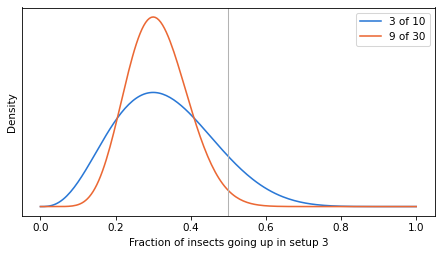

In [12]:
xs = np.linspace(0, 1, 201)
for (label, post), color in zip(posteriors.items(), [BLUE, ORANGE]):
    plt.plot(xs, post.pdf(xs), color=color, label=label)
plt.axvline(0.5, color="0.7", lw=1)
decorate(xlabel="Fraction of insects going up in setup 3", ylabel="Density", yticks=[])

With 10 insects, the probability that most insects follow the bait is about 0.89, but the credible interval runs from 0.14 to 0.56, so we don't know much about how strong the effect is. With 30 insects, the probability is about 0.99 and the interval is narrower, 0.19 to 0.45.

A Bayesian analysis also makes sequential data collection relatively straightforward. We can plan to look at the posterior after each batch of insects and stop when it reaches a threshold chosen in advance. Under the model, the posterior remains interpretable even when the decision to stop depends on earlier results. But posterior probabilities are not long-run error rates, so if we also want to control the chance of reaching a wrong conclusion, we should check the stopping rule by simulation before running the experiment.

## Would a fourth setup help?

The model can't connect setups 1 and 2 to setup 3, because each parameter is pinned down by one cell. Adding the missing cell -- bait at the top only -- gives four cells and three parameters, so the model can no longer fit every cell exactly, and the estimate for setup 3 can borrow information from the other cells. The cost is an assumption: the effects of bait at the top and bait at the bottom add up on the log-odds scale.

Suppose 9 of 10 go up in the fourth setup. Here's the additive model in PyMC, with weakly informative priors, and the posterior for the fraction going up in setup 3:

In [13]:
cells4 = pd.concat([
    cells.drop(columns="fraction up"),
    pd.DataFrame({"bait_top": [1], "bait_bottom": [0], "up": [9], "n": [10]}, index=pd.Index([4], name="setup")),
])

with pm.Model() as additive:
    a = pm.Normal("a", 0, 1.5)
    b_top = pm.Normal("b_top", 0, 1.5)
    b_bottom = pm.Normal("b_bottom", 0, 1.5)
    eta = a + b_top * cells4["bait_top"].values + b_bottom * cells4["bait_bottom"].values
    pm.Binomial("up", n=cells4["n"].values, logit_p=eta, observed=cells4["up"].values)
    pm.Deterministic("p3", pm.math.invlogit(a + b_bottom))
    idata = pm.sample(random_seed=1, progressbar=False)

NUTS[nutpie]: [a, b_top, b_bottom]


In [14]:
p3 = idata.posterior["p3"].values.ravel()
alone = posteriors["3 of 10"]
pd.DataFrame({
    "setup 3 alone": [alone.cdf(0.5), *alone.ppf([0.05, 0.95])],
    "additive model, 4 setups": [(p3 < 0.5).mean(), *np.quantile(p3, [0.05, 0.95])],
}, index=["P(fraction up < 0.5)", "90% CI low", "90% CI high"]).T.round(2)

,P(fraction up < 0.5),90% CI low,90% CI high
setup 3 alone,0.89,0.14,0.56
"additive model, 4 setups",0.88,0.17,0.56


The results are almost the same. The extra information about setup 3 is indirect: it comes from the other three cells (setup 1 + setup 2 − setup 4, on the log-odds scale), so it combines the uncertainty of three cells and is noisier than setup 3's own data. Here it doesn't move the posterior much.

So the fourth setup is worth adding for other reasons: it measures the pull of bait at the top separately from the up-bias, and with all four cells, we can estimate the interaction -- how far bait at both ends departs from the sum of the two effects. But for the main question, the way to get a clearer answer is more insects in setup 3.

## Discussion

To answer the question: the three setups can be combined in one logistic regression, but for the main hypothesis, the combined model gives the same answer as setup 3 alone. "Bait overcomes the preference for going up" means that, with bait only at the bottom, fewer than half the insects go up, and that's a question about one setup. Setups 1 and 2 describe the up-bias and the effect of bait at both ends, which are worth reporting, but they don't sharpen the main test.

With 10 insects per setup, a significance test is likely to come out non-significant even if the bait overcomes the up-bias. Before running the experiment, it would be worth increasing the number of insects in setup 3, or planning to add insects in batches until the posterior reaches a threshold chosen in advance.

[*Data Q&A: Answering the real questions with Python*](https://allendowney.github.io/DataQnA/index.html)

Copyright 2026 [Allen B. Downey](https://allendowney.com)

License: [Creative Commons Attribution-NonCommercial-ShareAlike 4.0 International](https://creativecommons.org/licenses/by-nc-sa/4.0/)